In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/faiss/D3/'

In [2]:
df_flat = pd.read_csv(main_dir + 'faiss_flat.csv')
df_flat['index'] = 'flat'
df_hnsw = pd.read_csv(main_dir + 'faiss_hnsw.csv')
df_hnsw['index'] = 'hnsw'
df_lsh = pd.read_csv(main_dir + 'faiss_lsh.csv')
df_lsh['index'] = 'lsh'

In [3]:
result = pd.DataFrame()
dfs = [df_flat, df_hnsw, df_lsh]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,FAISS FLAT Blocking,2935,1,28.82,76.77,41.91,846,2089,2931,256,flat,[title],1024,0,1,salted_qgrams,,4
1,FAISS FLAT Blocking,5870,2,16.29,86.75,27.42,956,4914,3041,146,flat,[title],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,8805,3,11.21,89.56,19.93,987,7818,3072,115,flat,[title],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,11740,4,8.60,91.65,15.73,1010,10730,3095,92,flat,[title],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,14675,5,6.93,92.29,12.89,1017,13658,3102,85,flat,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,17610,6,5.05,80.76,9.51,890,16720,2975,212,lsh,[title],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,20545,7,4.37,81.40,8.29,897,19648,2982,205,lsh,[title],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,23480,8,3.85,81.94,7.35,903,22577,2988,199,lsh,[title],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,26415,9,3.43,82.21,6.59,906,25509,2991,196,lsh,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    960
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    960
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    960
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    960
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    960
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     30
2     30
3     30
4     30
5     30
6     30
7     30
8     30
9     30
10    30
11    30
12    30
13    30
14    30
15    30
16    30
17    30
18    30
19    30
20    30
21    30
22    30
23    30
24    30
25    30
26    30
27    30
28    30
29    30
30    30
31    30
32    30
Name: count, dtype: int64

In [10]:
valid_rows = result[result['Recall %']>=80]
valid_rows

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
1,FAISS FLAT Blocking,5870,2,16.29,86.75,27.42,956,4914,3041,146,flat,[title],1024,0,1,salted_qgrams,,4
2,FAISS FLAT Blocking,8805,3,11.21,89.56,19.93,987,7818,3072,115,flat,[title],1024,0,1,salted_qgrams,,4
3,FAISS FLAT Blocking,11740,4,8.60,91.65,15.73,1010,10730,3095,92,flat,[title],1024,0,1,salted_qgrams,,4
4,FAISS FLAT Blocking,14675,5,6.93,92.29,12.89,1017,13658,3102,85,flat,[title],1024,0,1,salted_qgrams,,4
5,FAISS FLAT Blocking,17610,6,5.80,92.74,10.92,1022,16588,3107,80,flat,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,FAISS LSH Blocking,17610,6,5.05,80.76,9.51,890,16720,2975,212,lsh,[title],1024,0,32,salted_qgrams,,4
956,FAISS LSH Blocking,20545,7,4.37,81.40,8.29,897,19648,2982,205,lsh,[title],1024,0,32,salted_qgrams,,4
957,FAISS LSH Blocking,23480,8,3.85,81.94,7.35,903,22577,2988,199,lsh,[title],1024,0,32,salted_qgrams,,4
958,FAISS LSH Blocking,26415,9,3.43,82.21,6.59,906,25509,2991,196,lsh,[title],1024,0,32,salted_qgrams,,4


In [11]:
valid_rows['index'].value_counts()

index
flat    277
lsh     277
hnsw      9
Name: count, dtype: int64

In [12]:
max_f1 = valid_rows.loc[valid_rows.groupby(['num_hashes','index'])['F1 %'].idxmax()]
max_f1

,name,candidate_pairs,top_k,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,index,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
1,FAISS FLAT Blocking,5870,2,16.29,86.75,27.42,956,4914,3041,146,flat,[title],1024,0,1,salted_qgrams,,4
641,FAISS LSH Blocking,5870,2,16.25,86.57,27.37,954,4916,3039,148,lsh,[title],1024,0,1,salted_qgrams,,4
11,FAISS FLAT Blocking,5870,2,16.34,87.02,27.51,959,4911,3044,143,flat,[title],1024,0,2,salted_qgrams,,4
651,FAISS LSH Blocking,5870,2,16.34,87.02,27.51,959,4911,3044,143,lsh,[title],1024,0,2,salted_qgrams,,4
21,FAISS FLAT Blocking,5870,2,16.46,87.66,27.71,966,4904,3051,136,flat,[title],1024,0,3,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
933,FAISS LSH Blocking,11740,4,7.57,80.67,13.85,889,10851,2974,213,lsh,[title],1024,0,30,salted_qgrams,,4
304,FAISS FLAT Blocking,14675,5,6.04,80.49,11.24,887,13788,2972,215,flat,[title],1024,0,31,salted_qgrams,,4
944,FAISS LSH Blocking,14675,5,6.04,80.49,11.24,887,13788,2972,215,lsh,[title],1024,0,31,salted_qgrams,,4
315,FAISS FLAT Blocking,17610,6,5.05,80.76,9.51,890,16720,2975,212,flat,[title],1024,0,32,salted_qgrams,,4


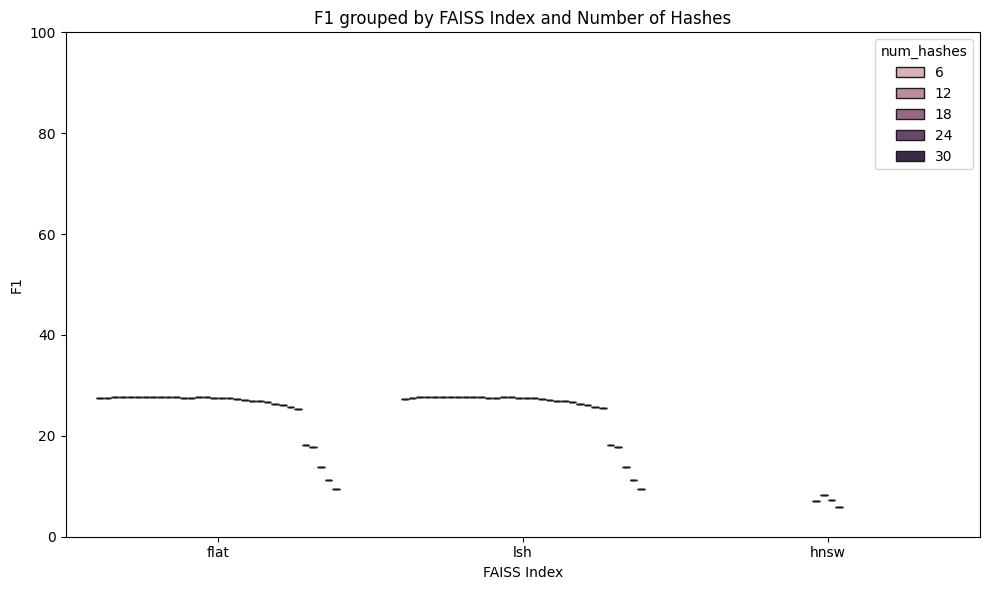

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="index",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by FAISS Index and Number of Hashes")
plt.xlabel("FAISS Index")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [14]:
metrics_df = max_f1.melt(
    id_vars=["index", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,index,num_hashes,Metric,Score
0,flat,1,Precision %,16.29
1,lsh,1,Precision %,16.25
2,flat,2,Precision %,16.34
3,lsh,2,Precision %,16.34
4,flat,3,Precision %,16.46
...,...,...,...,...
199,lsh,30,F1 %,13.85
200,flat,31,F1 %,11.24
201,lsh,31,F1 %,11.24
202,flat,32,F1 %,9.51


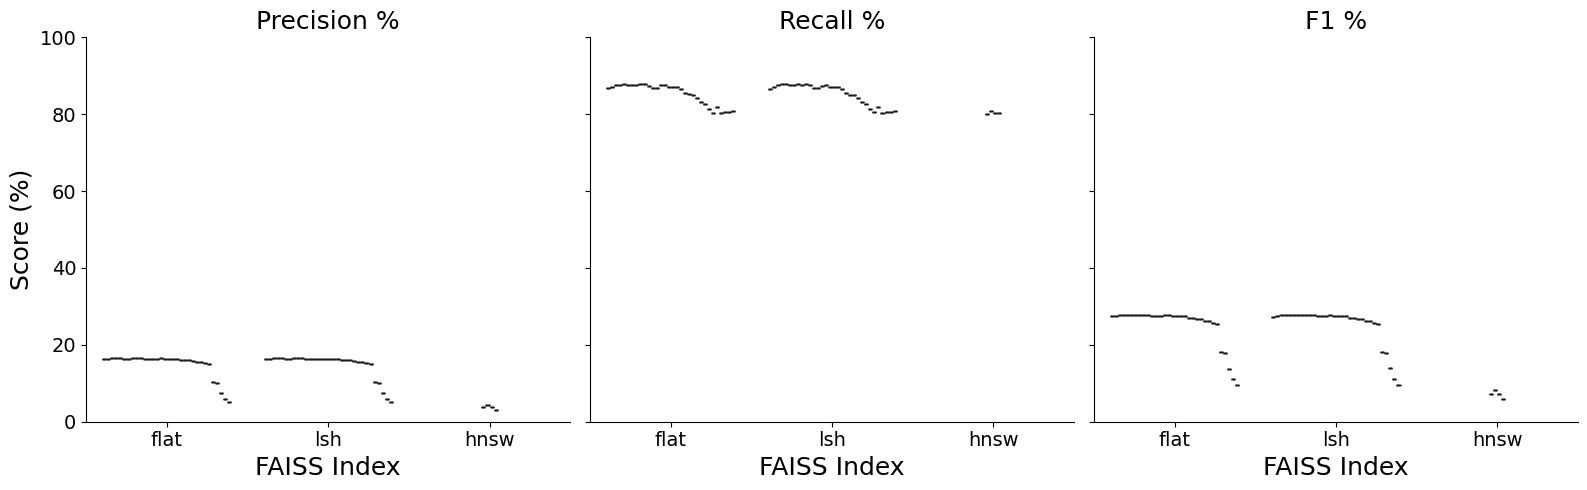

In [15]:
g = sns.catplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("FAISS Index", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

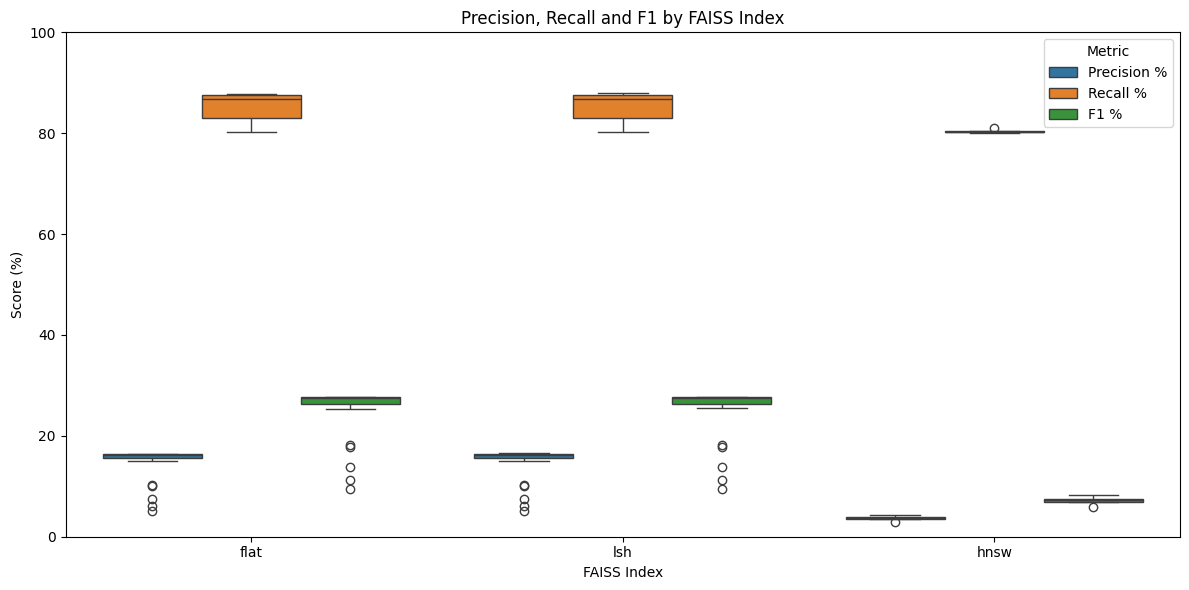

In [16]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="index",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by FAISS Index")
plt.xlabel("FAISS Index")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()